In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [3]:
data = [
    {"class": "negative", "text": "You are look so bad"},
    {"class": "positive", "text": "You Looking Good"},
    {"class": "negative", "text": "You look so Poor"},
    {"class": "positive", "text": "You are so handsome"},
    {"class": "positive", "text": "You are so Great"},
    {"class": "negative", "text": "Look Stupid"},
    {"class": "positive", "text": "You are look stupid but really Cool"},
    {"class": "positive", "text": "I thought this was going to be bad but you are actually doing a wonderful job"},
    {"class": "positive", "text": "You look incredibly handsome today and your outfit is just great"},
    {"class": "positive", "text": "You are not stupid at all you are actually brilliant and amazing"},
    {"class": "positive", "text": "Not bad at all you actually look pretty cool and stylish"},
    {"class": "positive", "text": "Even though the start was rough the final result is absolutely beautiful"},
    {"class": "positive", "text": "Looking good and feeling great about this whole situation"},
    {"class": "positive", "text": "This is not poor quality it is actually a fantastic piece of work"},
    {"class": "positive", "text": "Being with you is awesome even when things get crazy"},
    {"class": "positive", "text": "I love how you handle things you are the absolute best"},
    {"class": "positive", "text": "Wow you are so smart and really cool to hang out with"},
    {"class": "negative", "text": "You might think you look good but you actually look so bad"},
    {"class": "negative", "text": "This is a great example of something completely stupid and useless"},
    {"class": "negative", "text": "I hate to say it but you look so poor and your style is terrible"},
    {"class": "negative", "text": "This could have been awesome but you ruined it and now it is trash"},
    {"class": "negative", "text": "You are not cool you are just mean and awful to everyone"},
    {"class": "negative", "text": "I expected a handsome guy but you are just a gross disappointment"},
    {"class": "negative", "text": "This is not great it is definitely the worst thing I have ever seen"},
    {"class": "negative", "text": "What a completely boring and useless way to spend my time"},
    {"class": "negative", "text": "You are acting like a fool and looking really ugly right now"},
    {"class": "negative", "text": "You are so fuck up and your attitude is completely disgusting"},
    {"class": "positive", "text": "I'm not going to lie, you look absolutely stunning today"},
    {"class": "positive", "text": "That performance was sick! I've never seen anything better"},
    {"class": "positive", "text": "You aren't just good at this; you're a natural born leader"},
    {"class": "positive", "text": "Hard to believe how much you've improved, this is top-tier work"},
    {"class": "positive", "text": "Despite the mistakes, you handled the crowd with pure class"},
    {"class": "negative", "text": "I've seen much better work from someone with your experience"},
    {"class": "negative", "text": "You seem to be trying hard, but the result is still quite underwhelming"},
    {"class": "negative", "text": "It’s a shame that such a great opportunity was wasted like this"},
    {"class": "negative", "text": "Your lack of effort is showing and it’s honestly embarrassing"},
    {"class": "negative", "text": "I expected brilliance, but this is just mediocre at best"},
    {"class": "positive", "text": "You’re absolutely killing it in that suit!"},
    {"class": "positive", "text": "Goat status. Nobody is doing it like you right now"},
    {"class": "negative", "text": "This vibe is totally off and it's making me uncomfortable"},
    {"class": "negative", "text": "Major fail. You really dropped the ball on this one"},
    {"class": "negative", "text": "That's a hard pass from me; the quality is just trash"},
    {"class": "positive", "text": "Your energy is so infectious and bright"},
    {"class": "positive", "text": "Everything about this is perfect and well-thought-out"},
    {"class": "negative", "text": "You are incredibly rude and have no respect for others"},
    {"class": "negative", "text": "This is a disaster and a complete waste of resources"}
]
X = [item["text"] for item in data]
y = [item["class"] for item in data]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

print(len(data))

positive_phrases = [item["text"] for item in data if item["class"] == "positive"]
print(len(positive_phrases))
pos_class = []
for i in range(len(positive_phrases)):
    new_pos_phase = positive_phrases[i].split()
    for j in range(len(new_pos_phase)):
        pos_class.append(new_pos_phase[j])
print("word manipulation of possitive class :",pos_class)

negative_phase = [item["text"] for item in data if item["class"] == "negative"]
neg_class = []
for i in range(len(negative_phase)):
    new__neg_phase = negative_phase[i].split()
    for j in range(len(new__neg_phase)):
        neg_class.append(new__neg_phase[j])
print("word manipulation of negative class :",neg_class)

def vocabuary(sentiment):
    vocab = []
    for item in sentiment:
        if item not in vocab:
            vocab.append(item)
    return vocab

def word_count(vocab, sentiment):
    word = []
    for item in vocab:
        repeatness = sentiment.count(item)
        word.append(repeatness)
    return word

def prior_probability(class0, class1):
    pos_cl_num = len(class0)
    neg_cl_num = len(class1)
    prob_pos = pos_cl_num/ (pos_cl_num+neg_cl_num)
    prob_neg = neg_cl_num/ (pos_cl_num+neg_cl_num)
    return prob_pos, prob_neg

def likelyhood(repeat_word, sentiment, vocabuary, smooth_parameter):
    likelyhood = []
    for prob in range (0, len(vocabuary)):
        result = (repeat_word[prob] + smooth_parameter) / (len(sentiment) + len(vocabuary))
        likelyhood.append(result)
    return likelyhood

pos_vocab = [item.lower() for item in pos_class]
neg_vocab =[item.lower() for item in neg_class]

sentiment = pos_vocab + neg_vocab
vocab = vocabuary(sentiment=sentiment)

positive_wordcount = word_count(vocab, pos_vocab)
negative_wordcount = word_count(vocab, neg_class)

positive_prior, negative_prior = prior_probability(positive_phrases, negative_phase)


46
23
word manipulation of possitive class : ['You', 'Looking', 'Good', 'You', 'are', 'so', 'handsome', 'You', 'are', 'so', 'Great', 'You', 'are', 'look', 'stupid', 'but', 'really', 'Cool', 'I', 'thought', 'this', 'was', 'going', 'to', 'be', 'bad', 'but', 'you', 'are', 'actually', 'doing', 'a', 'wonderful', 'job', 'You', 'look', 'incredibly', 'handsome', 'today', 'and', 'your', 'outfit', 'is', 'just', 'great', 'You', 'are', 'not', 'stupid', 'at', 'all', 'you', 'are', 'actually', 'brilliant', 'and', 'amazing', 'Not', 'bad', 'at', 'all', 'you', 'actually', 'look', 'pretty', 'cool', 'and', 'stylish', 'Even', 'though', 'the', 'start', 'was', 'rough', 'the', 'final', 'result', 'is', 'absolutely', 'beautiful', 'Looking', 'good', 'and', 'feeling', 'great', 'about', 'this', 'whole', 'situation', 'This', 'is', 'not', 'poor', 'quality', 'it', 'is', 'actually', 'a', 'fantastic', 'piece', 'of', 'work', 'Being', 'with', 'you', 'is', 'awesome', 'even', 'when', 'things', 'get', 'crazy', 'I', 'love', 

In [9]:
phase = str(input("Enter the prediction line"))
#phase = "I thought this was going to be bad but you are actually doing a wonderful job You are so fuck up and your attitude is completely disgusting Looking good and feeling great about this whole situation"
split_phase = phase.split()
refine_split_phase = [item.lower() for item in split_phase]
for item in split_phase:
    if item == pos_class:
        break
predict = word_count(vocab=vocab, sentiment= refine_split_phase)
print(phase)

positive_likelihoods = likelyhood(
    repeat_word=positive_wordcount, 
    sentiment=pos_vocab, 
    vocabuary=vocab, 
    smooth_parameter=1
)
negative_likelihoods = likelyhood(
    repeat_word=negative_wordcount, 
    sentiment=neg_vocab, 
    vocabuary=vocab, 
    smooth_parameter=1
)
pos_score = positive_prior
neg_score = negative_prior
for word in refine_split_phase:
    if word in vocab:
        word_index = vocab.index(word)

        pos_score *= positive_likelihoods[word_index]
        neg_score *= negative_likelihoods[word_index]

print(f"\nPositive Score: {pos_score}")
print(f"Negative Score: {neg_score}")

if pos_score > neg_score:
    print("Prediction: positive with the score of", pos_score)
elif neg_score > pos_score:
    print("Prediction: negative with the score of", neg_score)
else:
    print("Indescribable")

Major fail. You really dropped the ball on this one

Positive Score: 5.426774246250478e-24
Negative Score: 2.1578471873823736e-23
Prediction: negative with the score of 2.1578471873823736e-23


In [22]:
#Model Evaluate

def predict_sentiment(text):
    refine_split_phase = [item.lower() for item in text.split()]
    pos_score = positive_prior
    neg_score = negative_prior
    for word in refine_split_phase:
        if word in vocab:
            word_index = vocab.index(word)
            pos_score *= positive_likelihoods[word_index]
            neg_score *= negative_likelihoods[word_index]
            
    if pos_score > neg_score:
        return "positive"
    elif neg_score > pos_score:
        return "negative"
    else:
        return "indescribable"

correct_predictions = 0
total_predictions = len(y_test)
y_pred = []
print("--- Testing Model on Unseen Data ---")

for i in range(total_predictions):
    test_text = X_test[i]
    actual_label = y_test[i]
    
    predicted_label = predict_sentiment(test_text)
    y_pred.append(predicted_label)
    
    print(f"\nText: '{test_text}'")
    print(f"Predicted: {predicted_label} | Actual: {actual_label}")
    
    if predicted_label == actual_label:
        print("Result: Correct")
        correct_predictions += 1
    else:
        print("Result: Incorrect")

accuracy = (correct_predictions / total_predictions) * 100

print("\n" + "="*30)
print(f"Accuracy: {accuracy:.2f}% ({correct_predictions}/{total_predictions})")
print("="*30)

--- Testing Model on Unseen Data ---

Text: 'This vibe is totally off and it's making me uncomfortable'
Predicted: negative | Actual: negative
Result: Correct

Text: 'You are acting like a fool and looking really ugly right now'
Predicted: negative | Actual: negative
Result: Correct

Text: 'You are so fuck up and your attitude is completely disgusting'
Predicted: negative | Actual: negative
Result: Correct

Text: 'You are incredibly rude and have no respect for others'
Predicted: negative | Actual: negative
Result: Correct

Text: 'Your lack of effort is showing and it’s honestly embarrassing'
Predicted: negative | Actual: negative
Result: Correct

Text: 'That's a hard pass from me; the quality is just trash'
Predicted: negative | Actual: negative
Result: Correct

Text: 'You are so Great'
Predicted: positive | Actual: positive
Result: Correct

Text: 'Looking good and feeling great about this whole situation'
Predicted: positive | Actual: positive
Result: Correct

Text: 'You look incredi

classification report:
              precision    recall  f1-score   support

    positive       1.00      1.00      1.00         5
    negative       1.00      1.00      1.00         9

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14

Confusion Matrix
True Positives:  5 | False Negatives: 0
False Positives: 0 | True Negatives:  9


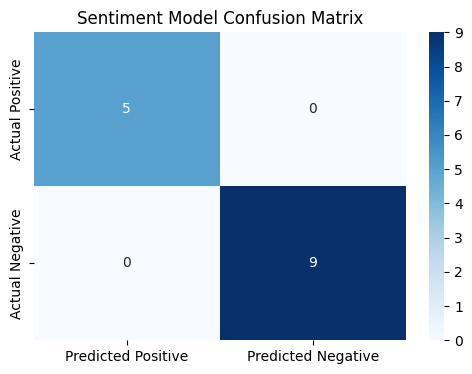

In [18]:
print("classification report:")
print(classification_report(y_test, y_pred, labels=["positive", "negative"]))

print("Confusion Matrix")
cm = confusion_matrix(y_test, y_pred, labels=["positive", "negative"])
print(f"True Positives:  {cm[0][0]} | False Negatives: {cm[0][1]}")
print(f"False Positives: {cm[1][0]} | True Negatives:  {cm[1][1]}")

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Predicted Positive", "Predicted Negative"], 
            yticklabels=["Actual Positive", "Actual Negative"])
plt.title("Sentiment Model Confusion Matrix")
plt.show()